# Geo-Spatial Supply Chain & Inventory Intelligence

Olist historical dataset analysis. Run from this notebook; paths are relative to the project root. No ML/AI is used.

## 1. Imports and file paths
The raw CSV files are kept unchanged in `data/raw/`. Install pandas, numpy, matplotlib and seaborn in your existing Python environment if needed.

In [1]:
# ==========================================
# PROJECT 4: GEO-SPATIAL SUPPLY CHAIN
# STEP 1: IMPORT LIBRARIES
# ==========================================

import os
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:,.2f}".format)

# Visualization settings
sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")
print("Python analysis environment is ready.")

All libraries imported successfully!
Python analysis environment is ready.


## 2. Load datasets

In [3]:
# STEP 2: LOAD ALL 9 DATASETS

# Notebook Python folder ke andar hai
PROJECT_ROOT = Path.cwd().parent

RAW = PROJECT_ROOT / "data" / "raw"
CLEANED = PROJECT_ROOT / "data" / "cleaned"
PROCESSED = PROJECT_ROOT / "data" / "processed"

CLEANED.mkdir(parents=True, exist_ok=True)
PROCESSED.mkdir(parents=True, exist_ok=True)

files = {
    "orders": "olist_orders_dataset.csv",
    "items": "olist_order_items_dataset.csv",
    "products": "olist_products_dataset.csv",
    "sellers": "olist_sellers_dataset.csv",
    "customers": "olist_customers_dataset.csv",
    "geolocation": "olist_geolocation_dataset.csv",
    "payments": "olist_order_payments_dataset.csv",
    "reviews": "olist_order_reviews_dataset.csv",
    "category_translation": "product_category_name_translation.csv"
}

data = {}

for name, filename in files.items():
    file_path = RAW / filename

    if not file_path.exists():
        print(f"MISSING: {filename}")
        continue

    df = pd.read_csv(file_path, encoding="utf-8-sig")
    data[name] = df

    print(f"{name:22s} | Rows: {len(df):,} | Columns: {len(df.columns)}")

print("\nDATASET LOADING COMPLETED!")
print("Successfully loaded:", len(data), "out of 9 datasets")

orders                 | Rows: 99,441 | Columns: 8
items                  | Rows: 112,650 | Columns: 7
products               | Rows: 32,951 | Columns: 9
sellers                | Rows: 3,095 | Columns: 4
customers              | Rows: 99,441 | Columns: 5
geolocation            | Rows: 1,000,163 | Columns: 5
payments               | Rows: 103,886 | Columns: 5
reviews                | Rows: 99,224 | Columns: 7
category_translation   | Rows: 71 | Columns: 2

DATASET LOADING COMPLETED!
Successfully loaded: 9 out of 9 datasets


## 3. Inspect schema, missing values and duplicates

In [4]:
# ==========================================
# STEP 3: DATA QUALITY ANALYSIS
# ==========================================

print("=" * 70)
print("          DATA QUALITY REPORT")
print("=" * 70)

quality_report = []

for name, df in data.items():

    total_rows = len(df)
    total_columns = len(df.columns)

    missing_values = df.isnull().sum().sum()
    duplicate_rows = df.duplicated().sum()

    missing_percentage = (
        (missing_values / (total_rows * total_columns)) * 100
        if total_rows * total_columns else 0
    )

    quality_report.append({
        "Dataset": name,
        "Rows": total_rows,
        "Columns": total_columns,
        "Missing Values": missing_values,
        "Missing %": round(missing_percentage, 2),
        "Duplicate Rows": duplicate_rows
    })

quality_df = pd.DataFrame(quality_report)

display(quality_df)

print("\nDATA QUALITY CHECK COMPLETED!")

          DATA QUALITY REPORT


,Dataset,Rows,Columns,Missing Values,Missing %,Duplicate Rows
0,orders,99441,8,4908,0.62,0
1,items,112650,7,0,0.00,0
2,products,32951,9,2448,0.83,0
3,sellers,3095,4,0,0.00,0
4,customers,99441,5,0,0.00,0
5,geolocation,1000163,5,0,0.00,261831
6,payments,103886,5,0,0.00,0
7,reviews,99224,7,145903,21.01,0
8,category_translation,71,2,0,0.00,0



DATA QUALITY CHECK COMPLETED!


## 4. Parse date columns and derive delivery metrics

In [5]:
# ==========================================
# STEP 4: DATE CLEANING & DELIVERY ANALYSIS
# ==========================================

orders = data["orders"].copy()

date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

# Convert columns into datetime
for col in date_columns:
    orders[col] = pd.to_datetime(orders[col], errors="coerce")

# Calculate delivery time in days
orders["delivery_days"] = (
    orders["order_delivered_customer_date"] -
    orders["order_purchase_timestamp"]
).dt.total_seconds() / 86400

# Calculate estimated delivery difference
orders["delivery_difference_days"] = (
    orders["order_delivered_customer_date"] -
    orders["order_estimated_delivery_date"]
).dt.total_seconds() / 86400

# Classify delivery performance
orders["delivery_status"] = np.select(
    [
        orders["delivery_difference_days"].isna(),
        orders["delivery_difference_days"] > 0,
        orders["delivery_difference_days"] <= 0
    ],
    [
        "Not Delivered",
        "Late",
        "On Time"
    ],
    default="Unknown"
)

print("AVERAGE DELIVERY TIME:",
      round(orders["delivery_days"].mean(), 2), "days")

print("\nDELIVERY PERFORMANCE:")
display(orders["delivery_status"].value_counts().to_frame("Orders"))

print("\nDATE ANALYSIS COMPLETED!")

AVERAGE DELIVERY TIME: 12.56 days

DELIVERY PERFORMANCE:


,Orders
delivery_status,
On Time,88649
Late,7827
Not Delivered,2965



DATE ANALYSIS COMPLETED!


## 5. Product demand and seller activity (historical order-item counts)

In [6]:
# ==========================================
# STEP 5: PRODUCT DEMAND & SELLER ANALYSIS
# ==========================================

# Copy original datasets
items = data["items"].copy()
products = data["products"].copy()
sellers = data["sellers"].copy()
categories = data["category_translation"].copy()

# Merge order items with product information
product_analysis = items.merge(
    products,
    on="product_id",
    how="left"
)

# Add English category names
product_analysis = product_analysis.merge(
    categories,
    on="product_category_name",
    how="left"
)

# Product-wise analysis
product_summary = (
    product_analysis
    .groupby(["product_id", "product_category_name_english"],
             dropna=False)
    .agg(
        Total_Orders=("order_id", "nunique"),
        Total_Items=("order_item_id", "count"),
        Average_Price=("price", "mean")
    )
    .reset_index()
    .sort_values("Total_Items", ascending=False)
)

print("TOP 10 PRODUCTS BY ORDERED ITEMS")
display(product_summary.head(10))

# Category-wise analysis
category_summary = (
    product_analysis
    .groupby("product_category_name_english", dropna=False)
    .agg(
        Total_Items=("order_item_id", "count"),
        Unique_Products=("product_id", "nunique")
    )
    .reset_index()
    .sort_values("Total_Items", ascending=False)
)

print("\nTOP 10 PRODUCT CATEGORIES")
display(category_summary.head(10))

# Seller-wise analysis
seller_summary = (
    items
    .groupby("seller_id")
    .agg(
        Total_Items=("order_item_id", "count"),
        Unique_Orders=("order_id", "nunique"),
        Total_Revenue=("price", "sum")
    )
    .reset_index()
    .sort_values("Total_Items", ascending=False)
)

print("\nTOP 10 SELLERS")
display(seller_summary.head(10))

print("\nPRODUCT AND SELLER ANALYSIS COMPLETED!")

TOP 10 PRODUCTS BY ORDERED ITEMS


,product_id,product_category_name_english,Total_Orders,Total_Items,Average_Price
22112,aca2eb7d00ea1a7b8ebd4e68314663af,furniture_decor,431,527,71.36
19742,99a4788cb24856965c36a24e339b6058,bed_bath_table,467,488,88.17
8613,422879e10f46682990de24d770e7f83d,garden_tools,352,484,54.91
7364,389d119b48cf3043d311335e499d9c6b,garden_tools,311,392,54.70
7079,368c6c730842d78016ad823897a372db,garden_tools,291,388,54.27
10840,53759a2ecddad2bb87a079a1f1519f73,garden_tools,287,373,54.66
27039,d1c427060a0f73f6b889a5c7c61f2ac4,computers_accessories,323,343,137.65
10867,53b36df67ebb7c41585e8d54d6772e08,watches_gifts,306,323,116.67
2794,154e7e31ebfa092203795c972e5804a6,health_beauty,269,281,22.51
8051,3dd2a17168ec895c781a9191c1e95ad7,computers_accessories,255,274,149.94



TOP 10 PRODUCT CATEGORIES


,product_category_name_english,Total_Items,Unique_Products
7,bed_bath_table,11115,3029
43,health_beauty,9670,2444
65,sports_leisure,8641,2867
39,furniture_decor,8334,2657
15,computers_accessories,7827,1639
49,housewares,6964,2335
70,watches_gifts,5991,1329
68,telephony,4545,1134
42,garden_tools,4347,753
5,auto,4235,1900



TOP 10 SELLERS


,seller_id,Total_Items,Unique_Orders,Total_Revenue
1235,6560211a19b47992c3666cc44a7e94c0,2033,1854,"123,304.83"
881,4a3ca9315b744ce9f8e9374361493884,1987,1806,"200,472.92"
368,1f50f920176fa81dab994f9023523100,1931,1404,"106,939.21"
2481,cc419e0650a3c5ba77189a1882b7556a,1775,1706,"104,288.42"
2643,da8622b14eb17ae2831f4ac5b9dab84a,1551,1314,"160,236.57"
1824,955fee9216a65b617aa5c0531780ce60,1499,1287,"135,171.70"
192,1025f0e2d44d7041d6cf58b6550e0bfa,1428,915,"138,968.55"
1535,7c67e1448b00f6e969d365cea6b010ab,1364,982,"187,923.89"
2836,ea8482cd71df3c1969d7b9473ff13abc,1203,1146,"37,177.52"
1505,7a67c85e85bb2ce8582c35f2203ad736,1171,1160,"141,745.53"



PRODUCT AND SELLER ANALYSIS COMPLETED!


## 6. Monthly order trend and visualizations

MONTHLY ORDER SUMMARY


,purchase_month,Total_Orders
0,2016-09,4
1,2016-10,324
2,2016-12,1
3,2017-01,800
4,2017-02,1780
5,2017-03,2682
6,2017-04,2404
7,2017-05,3700
8,2017-06,3245
9,2017-07,4026


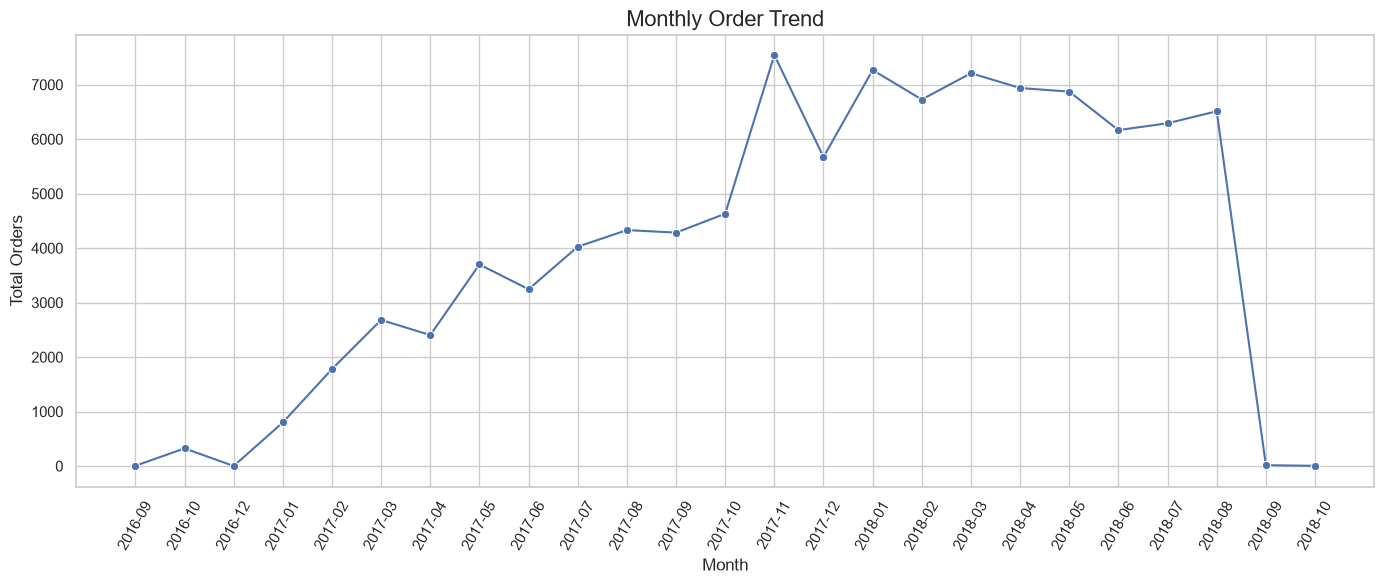

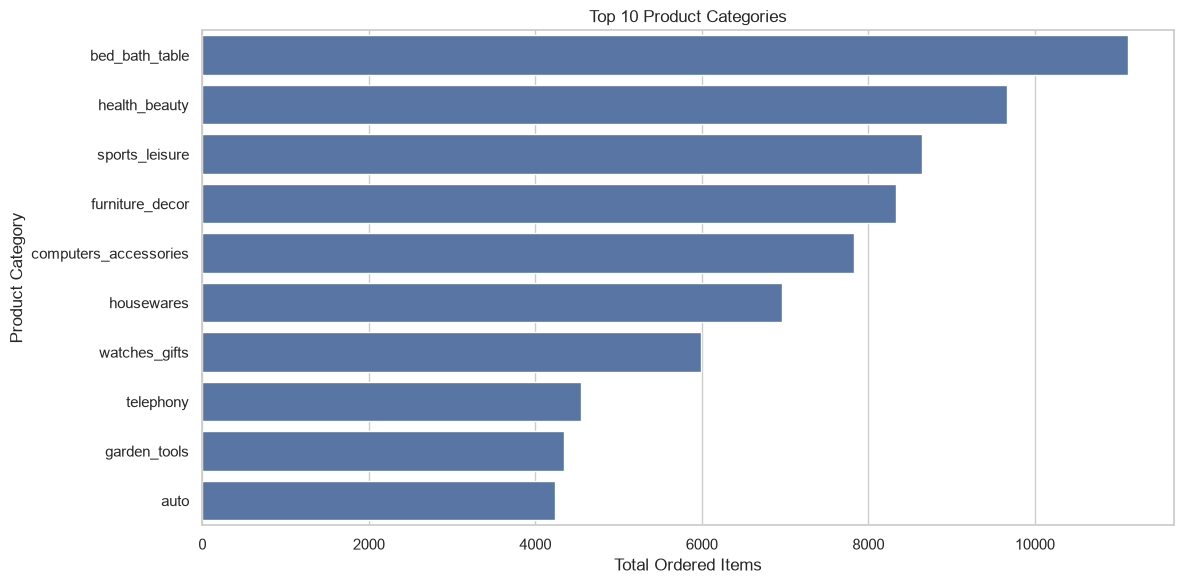

VISUALIZATION COMPLETED!


In [7]:
# ==========================================
# STEP 6: MONTHLY ORDER TREND ANALYSIS
# ==========================================

# Create monthly order column
orders["purchase_month"] = (
    orders["order_purchase_timestamp"]
    .dt.to_period("M")
    .astype("string")
)

# Monthly order summary
monthly_orders = (
    orders.groupby("purchase_month")
    .agg(
        Total_Orders=("order_id", "nunique")
    )
    .reset_index()
)

print("MONTHLY ORDER SUMMARY")
display(monthly_orders)

# Chart 1: Monthly Orders
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=monthly_orders,
    x="purchase_month",
    y="Total_Orders",
    marker="o"
)

plt.title("Monthly Order Trend", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Total Orders")
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

# Chart 2: Top 10 Product Categories
top_categories = category_summary.head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_categories,
    x="Total_Items",
    y="product_category_name_english"
)

plt.title("Top 10 Product Categories")
plt.xlabel("Total Ordered Items")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()

print("VISUALIZATION COMPLETED!")

## 7. Geographic seller distribution

SELLER DISTRIBUTION BY STATE


,seller_state,Total_Sellers
22,SP,1849
15,PR,349
8,MG,244
20,SC,190
16,RJ,171
19,RS,129
6,GO,40
4,DF,30
5,ES,23
2,BA,19


TOP 15 SELLER CITIES


,seller_state,seller_city,Total_Sellers
590,SP,sao paulo,694
166,PR,curitiba,124
238,RJ,rio de janeiro,93
57,MG,belo horizonte,66
555,SP,ribeirao preto,52
458,SP,guarulhos,50
461,SP,ibitinga,49
573,SP,santo andre,45
415,SP,campinas,41
188,PR,maringa,40


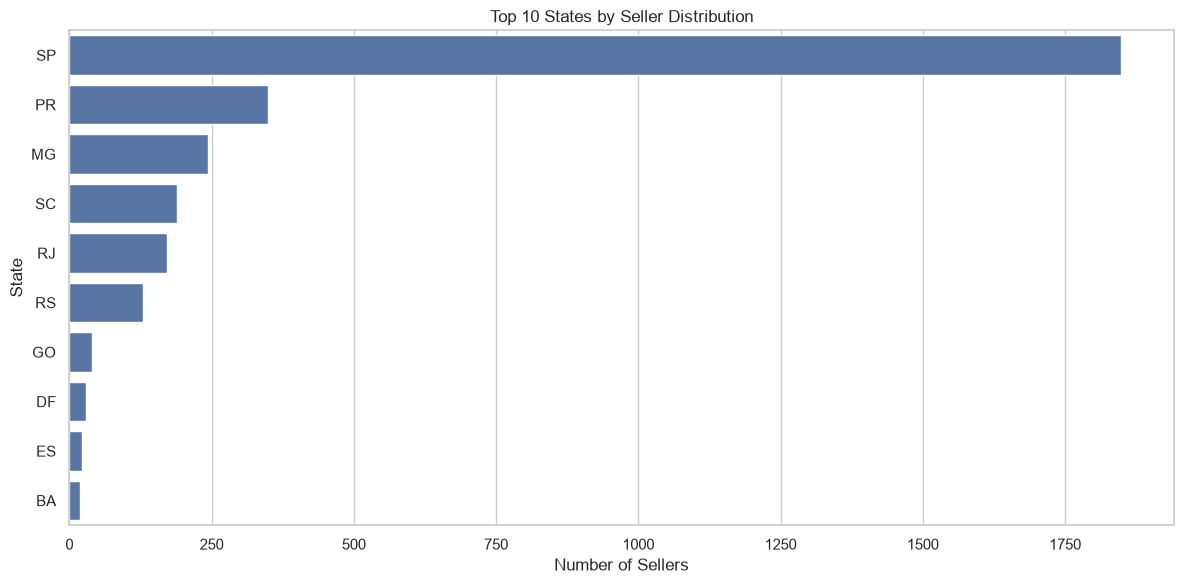

GEOGRAPHIC ANALYSIS COMPLETED!


In [8]:
# ==========================================
# STEP 7: GEOGRAPHIC SELLER ANALYSIS
# ==========================================

sellers = data["sellers"].copy()

# State-wise seller distribution
state_sellers = (
    sellers.groupby("seller_state")
    .agg(
        Total_Sellers=("seller_id", "nunique")
    )
    .reset_index()
    .sort_values("Total_Sellers", ascending=False)
)

print("SELLER DISTRIBUTION BY STATE")
display(state_sellers.head(15))


# City-wise seller distribution
city_sellers = (
    sellers.groupby(["seller_state", "seller_city"])
    .agg(
        Total_Sellers=("seller_id", "nunique")
    )
    .reset_index()
    .sort_values("Total_Sellers", ascending=False)
)

print("TOP 15 SELLER CITIES")
display(city_sellers.head(15))


# Visualization: Top 10 States
plt.figure(figsize=(12, 6))

sns.barplot(
    data=state_sellers.head(10),
    x="Total_Sellers",
    y="seller_state"
)

plt.title("Top 10 States by Seller Distribution")
plt.xlabel("Number of Sellers")
plt.ylabel("State")

plt.tight_layout()
plt.show()

print("GEOGRAPHIC ANALYSIS COMPLETED!")

## 8. Export reproducible analytical tables

In [9]:
# ==========================================
# STEP 8: EXPORT CLEANED & PROCESSED DATA
# ==========================================

# Export cleaned datasets
orders.to_csv(CLEANED / "cleaned_orders.csv", index=False, encoding="utf-8-sig")
items.to_csv(CLEANED / "cleaned_order_items.csv", index=False, encoding="utf-8-sig")

# Export analytical summaries
exports = {
    "data_quality_report": quality_df,
    "product_summary": product_summary,
    "category_summary": category_summary,
    "seller_summary": seller_summary,
    "monthly_orders": monthly_orders,
    "seller_state_summary": state_sellers,
    "seller_city_summary": city_sellers
}

for filename, df in exports.items():
    df.to_csv(
        PROCESSED / f"{filename}.csv",
        index=False,
        encoding="utf-8-sig"
    )
    print(f"Exported: {filename}.csv")

# Verify exported files
print("\nCLEANED FILES:")
for file in CLEANED.glob("*.csv"):
    print(file.name)

print("\nPROCESSED FILES:")
for file in PROCESSED.glob("*.csv"):
    print(file.name)

print("\nPYTHON DATA EXPORT COMPLETED!")


Exported: data_quality_report.csv
Exported: product_summary.csv
Exported: category_summary.csv
Exported: seller_summary.csv
Exported: monthly_orders.csv
Exported: seller_state_summary.csv
Exported: seller_city_summary.csv

CLEANED FILES:
cleaned_orders.csv
cleaned_order_items.csv

PROCESSED FILES:
category_summary.csv
data_quality_report.csv
monthly_orders.csv
product_summary.csv
seller_city_summary.csv
seller_state_summary.csv
seller_summary.csv

PYTHON DATA EXPORT COMPLETED!


In [10]:
monthly_orders["purchase_month"] = (
    monthly_orders["purchase_month"].astype(str)
)

print("MONTHLY ORDER DISTRIBUTION")
display(
    monthly_orders[
        monthly_orders["Total_Orders"] <= 10
    ]
)

print("TOTAL MONTHS:", len(monthly_orders))

print(
    "MONTHS WITH 10 OR FEWER ORDERS:",
    len(monthly_orders[monthly_orders["Total_Orders"] <= 10])
)

MONTHLY ORDER DISTRIBUTION


,purchase_month,Total_Orders
0,2016-09,4
2,2016-12,1
24,2018-10,4


TOTAL MONTHS: 25
MONTHS WITH 10 OR FEWER ORDERS: 3


In [11]:
# Check monthly date coverage

for month in ["2016-09", "2016-12", "2018-10"]:
    month_data = orders[
        orders["order_purchase_timestamp"].dt.strftime("%Y-%m") == month
    ]

    print(f"\nMONTH: {month}")
    print("Total orders:", month_data["order_id"].nunique())

    if not month_data.empty:
        print("First order:", month_data["order_purchase_timestamp"].min())
        print("Last order:", month_data["order_purchase_timestamp"].max())


MONTH: 2016-09
Total orders: 4
First order: 2016-09-04 21:15:19
Last order: 2016-09-15 12:16:38

MONTH: 2016-12
Total orders: 1
First order: 2016-12-23 23:16:47
Last order: 2016-12-23 23:16:47

MONTH: 2018-10
Total orders: 4
First order: 2018-10-01 15:30:09
Last order: 2018-10-17 17:30:18


## Interpretation and limitations
- `historical_items_ordered` is a count of order-item rows, not actual warehouse stock consumption.
- Seller delivery metrics are attributed at order level to each seller appearing in that order; multi-seller orders can therefore contribute to multiple sellers.
- Olist does not provide stock-on-hand snapshots, inventory ageing, supplier lead-time master data, safety stock, outstanding purchase orders or unit cost.
- Do not label derived demand as actual inventory depletion, and do not claim stock-out frequency or inventory turnover from this dataset.

In [12]:
# FINAL DATA QUALITY INSPECTION

print("MISSING VALUES BY COLUMN")
for name, df in data.items():
    missing = df.isnull().sum()
    missing = missing[missing > 0]

    if len(missing) > 0:
        print(f"\n{name.upper()}")
        display(missing.to_frame("Missing Values"))

print("\nGELOCATION DUPLICATE CHECK")
geo = data["geolocation"]

print("Total rows:", len(geo))
print("Exact duplicate rows:", geo.duplicated().sum())
print("Unique ZIP prefixes:", geo["geolocation_zip_code_prefix"].nunique())

MISSING VALUES BY COLUMN

ORDERS


,Missing Values
order_approved_at,160
order_delivered_carrier_date,1783
order_delivered_customer_date,2965



PRODUCTS


,Missing Values
product_category_name,610
product_name_lenght,610
product_description_lenght,610
product_photos_qty,610
product_weight_g,2
product_length_cm,2
product_height_cm,2
product_width_cm,2



REVIEWS


,Missing Values
review_comment_title,87656
review_comment_message,58247



GELOCATION DUPLICATE CHECK
Total rows: 1000163
Exact duplicate rows: 261831
Unique ZIP prefixes: 19015
